# Ouroboros training (Colab T4)

Runtime -> Change runtime type -> **T4 GPU**, then run all cells top to bottom.

Same notebook for the first session and after a disconnect: the data cell reuses the
token cache on Drive, and the train cell resumes from `latest.pt` if one exists.

Logs append to `MyDrive/ouroboros/main.log`. W&B is optional (see its cell).

In [1]:
# check the GPU
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
# mount Drive: checkpoints and the token cache live here so they survive disconnects
from google.colab import drive

drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive/ouroboros"
CKPT_DIR = f"{DRIVE}/checkpoints"
RUN_NAME = "main"
!mkdir -p {CKPT_DIR}

Mounted at /content/drive


In [3]:
# get the code (pull if this session already cloned it)
import os

if os.path.exists("/content/Ouroboros"):
    !git -C /content/Ouroboros pull
else:
    !git clone https://github.com/asherk7/Ouroboros.git /content/Ouroboros
%cd /content/Ouroboros
!pip install -q -e .

Cloning into '/content/Ouroboros'...
remote: Enumerating objects: 229, done.
remote: Counting objects: 100% (229/229), done.
remote: Compressing objects: 100% (123/123), done.
remote: Total 229 (delta 126), reused 197 (delta 97), pack-reused 0 (from 0)
Receiving objects: 100% (229/229), 248.76 KiB | 17.77 MiB/s, done.
Resolving deltas: 100% (126/126), done.
/content/Ouroboros
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ouroboros (pyproject.toml) ... done


In [4]:
# tokenizer + token cache: copy from Drive if saved, else build once (~10-20 min) and save.
# training reads it from local disk; shuffled reads through the Drive mount are slow
if os.path.exists(f"{DRIVE}/data/train.bin"):
    !cp -r {DRIVE}/data .
else:
    !python -c "import sys; sys.path.insert(0, 'training'); import train as t; c = t.TrainConfig(); t.train_tokenizer(c, t.OuroborosConfig().vocab_size); t.tokenize_split(c, 'train'); t.tokenize_split(c, 'validation')"
    !cp -r data {DRIVE}/
!ls -lh data

training tokenizer (8192 tokens) on roneneldan/TinyStories...
README.md: 100% 1.06k/1.06k [00:00<00:00, 3.19MB/s]
[00:00:00] Tokenize words                 ██████████████████ 76025    /    76025
[00:00:00] Count pairs                    ██████████████████ 76025    /    76025
[00:00:00] Compute merges                 ██████████████████ 7935     /     7935
tokenizing train split...
train: 466,735,384 tokens -> data/train.bin
tokenizing validation split...
validation: 4,691,062 tokens -> data/validation.bin
total 900M
-rw-r--r-- 1 root root 541K Oct 23 21:26 tokenizer.json
-rw-r--r-- 1 root root 891M Oct 23 21:43 train.bin
-rw-r--r-- 1 root root 9.0M Oct 23 21:43 validation.bin


In [5]:
# optional W&B: set True and add WANDB_API_KEY under Colab's 🔑 Secrets.
# without it, metrics go to stdout and to train.log on Drive (survives disconnects)
USE_WANDB = False

wandb_flag = ""
if USE_WANDB:
    from google.colab import userdata

    os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
    wandb_flag = f"--wandb-project ouroboros --run-name {RUN_NAME}"


In [6]:
# train, resuming if a checkpoint exists. -u + tee: logs stream live and append to Drive
latest = f"{CKPT_DIR}/latest.pt"
resume = f"--resume {latest}" if os.path.exists(latest) else ""
print("resuming from", latest if resume else "nothing (fresh run)")

!python -u training/train.py --ckpt-dir {CKPT_DIR} {wandb_flag} {resume} 2>&1 | tee -a {DRIVE}/{RUN_NAME}.log

resuming from nothing (fresh run)
model: 19.80M params on cuda
step 10 | loss 8.51 | grad_norm 4.173 | lr 5e-05 | n_loops 2 | tokens_per_s 1.671e+04 | expert_load_var 0.02773 | rho_A 0.368 | A_mean 0.3679 | A_min 0.3678
step 20 | loss 7.638 | grad_norm 2.375 | lr 0.0001 | n_loops 8 | tokens_per_s 1.849e+04 | expert_load_var 0.04862 | rho_A 0.368 | A_mean 0.3676 | A_min 0.3673
step 30 | loss 6.996 | grad_norm 1.881 | lr 0.00015 | n_loops 11 | tokens_per_s 1.557e+04 | expert_load_var 0.03912 | rho_A 0.3682 | A_mean 0.3674 | A_min 0.3669
step 40 | loss 6.246 | grad_norm 1.086 | lr 0.0002 | n_loops 3 | tokens_per_s 1.758e+04 | expert_load_var 0.03851 | rho_A 0.369 | A_mean 0.3678 | A_min 0.3669
step 50 | loss 5.69 | grad_norm 2.092 | lr 0.00025 | n_loops 9 | tokens_per_s 1.644e+04 | expert_load_var 0.03606 | rho_A 0.3698 | A_mean 0.368 | A_min 0.3666
step 60 | loss 5.288 | grad_norm 1.171 | lr 0.0003 | n_loops 4 | tokens_per_s 1.807e+04 | expert_load_var 0.0253 | rho_A 0.3709 | A_mean 0.36

**Watch for the first ~15 min:** loss starts near 9.0 and falls; grad_norm mostly ≤ ~1;
rho_A < 1; n_loops varies; expert_load_var trends down; val_ppl every 500 steps.

ETA = (5000 - step) × 32768 / tokens_per_s seconds.

In [7]:
# ===== results: run after training finishes =====
# pull the metric scripts and set up paths
%cd /content/Ouroboros
!git pull
!pip install -q -e .

import os
import re
import sys
import matplotlib.pyplot as plt
from IPython.display import Image, display

FINAL = f"{CKPT_DIR}/final.pt"
RESULTS = f"{DRIVE}/results"
!mkdir -p {RESULTS}


/content/Ouroboros
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 6 (delta 2), reused 6 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 4.04 KiB | 1.34 MiB/s, done.
From https://github.com/asherk7/Ouroboros
   8f7822f..0e18ebb  main       -> origin/main
Updating 8f7822f..0e18ebb
Fast-forward
 training/kv_speedup.py | 59 +++++++++++++++++++++++++++++++++-------
 training/loop_sweep.py | 73 +++++++++++++++++++++++++++++++++++++++++---------
 training/train.py      | 11 ++++++++
 3 files changed, 121 insertions(+), 22 deletions(-)
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ouroboros (pyproject.toml) ... done


In [10]:
# sanity check: sample a few stories
import torch
from tokenizers import Tokenizer

sys.path.insert(0, "training")
from train import load_model

model, _ = load_model(FINAL, "cuda")
tok = Tokenizer.from_file("data/tokenizer.json")
for prompt in ["Once upon a time", "Tom and his dog", "The little girl was sad because"]:
    ids = torch.tensor([tok.encode(prompt).ids], device="cuda")
    out = model.generate(ids, max_new_tokens=150, temperature=0.8, top_k=50)
    text = tok.decode(out[0].tolist(), skip_special_tokens=False)
    print(text.split("<|endoftext|>")[0].strip(), "\n---")


Once upon a time, there was a wise old frog. He lived in a pond with lots of other frogs. The wise frog wanted to teach the animals that they were good friends.

One day, the wise frog said, "We could all learn together today. Let's all play a game, and see who can whistle the loudest." All the frogs agreed, and they started whistling their favorite song.

The wise frog, the wise frog, and the animals all got started. They all whistled as loud as they could. The wise frog and the animals were very happy. They loved their loud song, and they knew that it would make the wise frog feel so happy. 
---
Tom and his dog, Spot. The dog and Spot are friends. They like to play in the park. They run and jump and wave at the ducks. They have fun.

One day, Tom sees a squirrel in the park. The squirrel is small and brown and has a long tail. The squirrel runs to the squirrel and jumps on his head. Tom laughs and says, "Look, a squirrel! He is so big and brown and has a long tail."

Sara and Tom wan

In [11]:
# metric 2: stability runs (~35 min each). own ckpt dirs and logs, so they never resume
# from the main run. skips a run whose final.pt already exists. if neither diverges,
# set STAB_LR = "1e-2" and rerun (new names, so nothing is overwritten)
STAB_LR = "3e-3"
for name, flag in [(f"lti-lr{STAB_LR}", ""), (f"naive-lr{STAB_LR}", "--no-lti")]:
    ckpt = f"{DRIVE}/stability/{name}"
    if os.path.exists(f"{ckpt}/final.pt"):
        print(f"{name}: already done")
        continue
    !python -u training/train.py --lr {STAB_LR} --max-steps 1000 --ckpt-dir {ckpt} {flag} 2>&1 | tee {DRIVE}/{name}.log


model: 19.80M params on cuda
step 10 | loss 7.96 | grad_norm 2.974 | lr 0.00015 | n_loops 2 | tokens_per_s 1.707e+04 | expert_load_var 0.03466 | rho_A 0.368 | A_mean 0.3677 | A_min 0.3674
step 20 | loss 6.773 | grad_norm 1.731 | lr 0.0003 | n_loops 8 | tokens_per_s 1.768e+04 | expert_load_var 0.02927 | rho_A 0.3682 | A_mean 0.3671 | A_min 0.3664
step 30 | loss 5.814 | grad_norm 0.5876 | lr 0.00045 | n_loops 11 | tokens_per_s 1.51e+04 | expert_load_var 0.03735 | rho_A 0.3695 | A_mean 0.3676 | A_min 0.3659
step 40 | loss 5.631 | grad_norm 0.8962 | lr 0.0006 | n_loops 3 | tokens_per_s 1.706e+04 | expert_load_var 0.0373 | rho_A 0.3705 | A_mean 0.3683 | A_min 0.3659
step 50 | loss 5.185 | grad_norm 0.7003 | lr 0.00075 | n_loops 9 | tokens_per_s 1.597e+04 | expert_load_var 0.03212 | rho_A 0.372 | A_mean 0.3689 | A_min 0.3659
step 60 | loss 4.808 | grad_norm 0.615 | lr 0.0009 | n_loops 4 | tokens_per_s 1.769e+04 | expert_load_var 0.03437 | rho_A 0.3731 | A_mean 0.3697 | A_min 0.3659
step 70 |

lti-lr3e-3: final loss 1.870, min 1.799, diverged at step never
naive-lr3e-3: final loss 1.782, min 1.707, diverged at step never


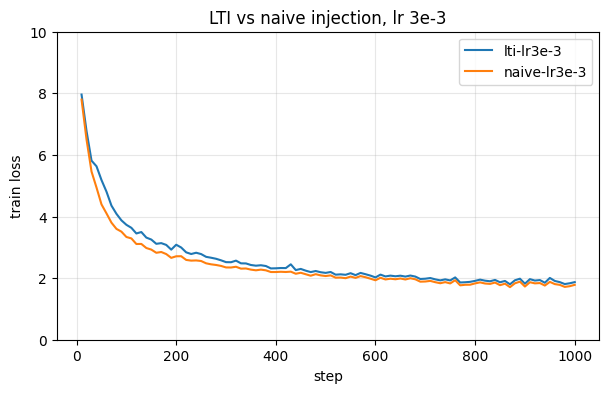

In [12]:
# plot the stability loss curves from the logs + summary
def read_log(path):
    steps, losses = [], []
    for line in open(path):
        m = re.match(r"step (\d+) \| loss (\S+)", line)
        if m:
            steps.append(int(m[1]))
            losses.append(float(m[2]))  # float() parses "nan" / "inf" too
    return steps, losses


fig, ax = plt.subplots(figsize=(7, 4))
for name in [f"lti-lr{STAB_LR}", f"naive-lr{STAB_LR}"]:
    steps, losses = read_log(f"{DRIVE}/{name}.log")
    ax.plot(steps, losses, label=name)
    # nan (nan != nan) or blown up
    bad = [s for s, loss in zip(steps, losses) if loss != loss or loss > 20]
    print(
        f"{name}: final loss {losses[-1]:.3f}, min {min(losses):.3f}, "
        f"diverged at step {bad[0] if bad else 'never'}"
    )
ax.set_xlabel("step")
ax.set_ylabel("train loss")
ax.set_ylim(0, 10)
ax.legend()
ax.grid(alpha=0.3)
ax.set_title(f"LTI vs naive injection, lr {STAB_LR}")
fig.savefig(f"{RESULTS}/stability_lr{STAB_LR}.png", dpi=150)
plt.show()

In [13]:
# metric 3: KV-cache decode speedup (8 loops, 256 new tokens, batch 1)
!python -u training/kv_speedup.py --ckpt {FINAL} 2>&1 | tee {RESULTS}/kv_speedup.txt


with cache:    31.0 tokens/s
without cache: 21.2 tokens/s
speedup: 1.46x (8 loops)


In [15]:
!python -u training/kv_speedup.py --ckpt {FINAL} --max-new-tokens 448 2>&1 | tee {RESULTS}/kv_speedup_448.txt


with cache:    30.4 tokens/s
without cache: 20.6 tokens/s
speedup: 1.48x (8 loops)


loops   1 | val_ppl 5.288
loops   2 | val_ppl 4.873
loops   4 | val_ppl 4.786
loops   8 | val_ppl 4.780
loops  16 | val_ppl 4.781
loops  32 | val_ppl 4.784
loops  64 | val_ppl 4.787

1 loop: 5.288 | best: 4.780 at 8 loops | 64 loops: 4.787
plot -> /content/drive/MyDrive/ouroboros/results/loop_sweep.png


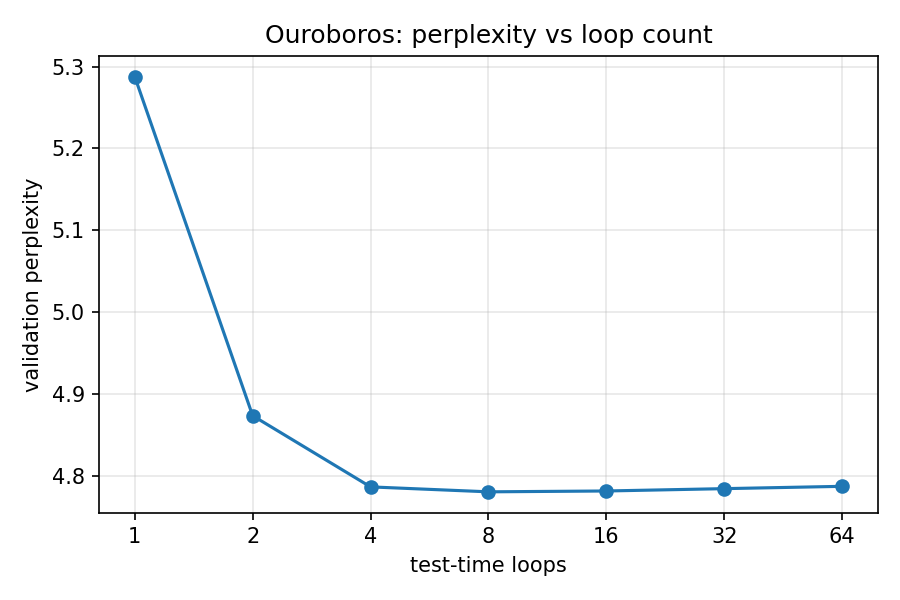

In [14]:
# metric 1: test-time loop sweep (~10-20 min). same 100 val batches at every loop count
!python -u training/loop_sweep.py --ckpt {FINAL} --out {RESULTS}/loop_sweep.png 2>&1 | tee {RESULTS}/loop_sweep.txt
display(Image(f"{RESULTS}/loop_sweep.png"))
